# 05b – Model improvements

Can feature engineering and monotonic constraints improve XGBoost?
Each change is added one at a time and measured with 5-fold stratified cross-validation.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import roc_auc_score, brier_score_loss
from scipy.stats import ks_2samp
from xgboost import XGBClassifier

train = pd.read_csv("../data/processed/train.csv")
test = pd.read_csv("../data/processed/test.csv")

target = "SeriousDlqin2yrs"
X_train, y_train = train.drop(columns=target), train[target]
X_test, y_test = test.drop(columns=target), test[target]

def evaluar(nombre, y_real, pd_estimada):
    """Discrimination and calibration metrics for a PD model."""
    auc = roc_auc_score(y_real, pd_estimada)
    ks = ks_2samp(pd_estimada[y_real == 1], pd_estimada[y_real == 0]).statistic
    return {"Model": nombre, "AUC": round(auc, 4), "Gini": round(2 * auc - 1, 4),
            "KS": round(ks, 4), "Brier": round(brier_score_loss(y_real, pd_estimada), 4),
            "Avg PD": round(pd_estimada.mean(), 4)}

print(X_train.shape, X_test.shape, len(y_train), len(y_test))

(119999, 14) (30000, 14) 119999 30000


## 1. Feature engineering
New variables with economic meaning, computed row by row (no information from other borrowers, so no leakage).

In [2]:
mora = ["NumberOfTime30-59DaysPastDueNotWorse",
        "NumberOfTime60-89DaysPastDueNotWorse",
        "NumberOfTimes90DaysLate"]

def agregar_variables(df):
    """Adds engineered features to a copy of the dataset."""
    df = df.copy()
    df["total_past_due"] = df[mora].sum(axis=1)
    df["ever_late"] = (df["total_past_due"] > 0).astype(int)
    df["monthly_debt"] = df["DebtRatio"] * df["MonthlyIncome"]
    df["income_per_person"] = df["MonthlyIncome"] / (df["NumberOfDependents"] + 1)
    df["non_real_estate_lines"] = (df["NumberOfOpenCreditLinesAndLoans"]
                                   - df["NumberRealEstateLoansOrLines"]).clip(lower=0)
    return df

X_train_fe = agregar_variables(X_train)
X_test_fe = agregar_variables(X_test)

print(X_train_fe.shape)
X_train_fe[["total_past_due", "ever_late", "monthly_debt",
            "income_per_person", "non_real_estate_lines"]].describe().round(2)

(119999, 19)


,total_past_due,ever_late,monthly_debt,income_per_person,non_real_estate_lines
count,119999.0,119999.0,119999.00,119999.00,119999.00
mean,0.4,0.2,1993.29,4425.02,7.44
std,1.1,0.4,3433.95,3181.91,4.77
min,0.0,0.0,0.00,0.00,0.00
25%,0.0,0.0,819.78,2160.00,4.00
50%,0.0,0.0,1602.42,4000.00,7.00
75%,0.0,0.0,2503.69,5400.00,10.00
max,19.0,1.0,474639.29,23018.30,57.00


## 2. Cross-validation: baseline vs. new features

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def nuevo_xgb(**extra):
    """XGBoost with the parameters of notebook 04, plus optional extra settings."""
    return XGBClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=4,
        subsample=0.8, colsample_bytree=0.8,
        eval_metric="logloss", random_state=42, n_jobs=-1, **extra,
    )

def evaluar_cv(nombre, modelo, X, y):
    """Mean and std of AUC and Brier over 5 stratified folds."""
    s = cross_validate(modelo, X, y, cv=cv,
                       scoring={"AUC": "roc_auc", "Brier": "neg_brier_score"})
    return {"Model": nombre,
            "AUC mean": s["test_AUC"].mean().round(4),
            "AUC std": s["test_AUC"].std().round(4),
            "Brier mean": (-s["test_Brier"]).mean().round(4)}

resultados_cv = [
    evaluar_cv("A. Baseline", nuevo_xgb(), X_train, y_train),
    evaluar_cv("B. + New features", nuevo_xgb(), X_train_fe, y_train),
]
pd.DataFrame(resultados_cv)

,Model,AUC mean,AUC std,Brier mean
0,A. Baseline,0.8647,0.0057,0.0491
1,B. + New features,0.8648,0.0056,0.0490


## 3. Monotonic constraints
Force economically sensible directions: more past-due events or utilization can never lower the PD; more age or income can never raise it.

In [4]:
direcciones = {
    # +1: a mayor valor, la PD solo puede subir
    "RevolvingUtilizationOfUnsecuredLines": 1,
    "NumberOfTime30-59DaysPastDueNotWorse": 1,
    "NumberOfTime60-89DaysPastDueNotWorse": 1,
    "NumberOfTimes90DaysLate": 1,
    "total_past_due": 1,
    "ever_late": 1,
    "DebtRatio": 1,
    "special_code": 1,
    # -1: a mayor valor, la PD solo puede bajar
    "age": -1,
    "MonthlyIncome": -1,
    "income_per_person": -1,
}
# El resto queda libre (0), por ejemplo las líneas de crédito, que tienen forma de U
restricciones = tuple(direcciones.get(col, 0) for col in X_train_fe.columns)

resultados_cv.append(
    evaluar_cv("C. + Monotonic constraints",
               nuevo_xgb(monotone_constraints=restricciones), X_train_fe, y_train)
)
pd.DataFrame(resultados_cv)

,Model,AUC mean,AUC std,Brier mean
0,A. Baseline,0.8647,0.0057,0.0491
1,B. + New features,0.8648,0.0056,0.0490
2,C. + Monotonic constraints,0.8636,0.0065,0.0493


In [5]:
direcciones_sin_ingreso = {k: v for k, v in direcciones.items()
                           if k not in ["MonthlyIncome", "income_per_person"]}
restricciones_2 = tuple(direcciones_sin_ingreso.get(col, 0) for col in X_train_fe.columns)

resultados_cv.append(
    evaluar_cv("C2. Monotonic, income free",
               nuevo_xgb(monotone_constraints=restricciones_2), X_train_fe, y_train)
)
pd.DataFrame(resultados_cv)

,Model,AUC mean,AUC std,Brier mean
0,A. Baseline,0.8647,0.0057,0.0491
1,B. + New features,0.8648,0.0056,0.0490
2,C. + Monotonic constraints,0.8636,0.0065,0.0493
3,"C2. Monotonic, income free",0.8636,0.0064,0.0493


In [6]:
direcciones_3 = {k: v for k, v in direcciones.items()
                 if k != "RevolvingUtilizationOfUnsecuredLines"}
restricciones_3 = tuple(direcciones_3.get(col, 0) for col in X_train_fe.columns)

resultados_cv.append(
    evaluar_cv("C3. Monotonic, utilization free",
               nuevo_xgb(monotone_constraints=restricciones_3), X_train_fe, y_train)
)
pd.DataFrame(resultados_cv)

,Model,AUC mean,AUC std,Brier mean
0,A. Baseline,0.8647,0.0057,0.0491
1,B. + New features,0.8648,0.0056,0.0490
2,C. + Monotonic constraints,0.8636,0.0065,0.0493
3,"C2. Monotonic, income free",0.8636,0.0064,0.0493
4,"C3. Monotonic, utilization free",0.8643,0.0060,0.0492


In [7]:
finales = {
    "A. Baseline": (nuevo_xgb(), X_train, X_test),
    "C3. Features + monotonic (util. free)": (
        nuevo_xgb(monotone_constraints=restricciones_3), X_train_fe, X_test_fe),
}

resultados_test = []
for nombre, (modelo, Xtr, Xte) in finales.items():
    modelo.fit(Xtr, y_train)
    resultados_test.append(evaluar(nombre, y_test, modelo.predict_proba(Xte)[:, 1]))

pd.DataFrame(resultados_test)

,Model,AUC,Gini,KS,Brier,Avg PD
0,A. Baseline,0.8695,0.7389,0.5847,0.0487,0.0669
1,C3. Features + monotonic (util. free),0.8697,0.7395,0.5871,0.0487,0.0671


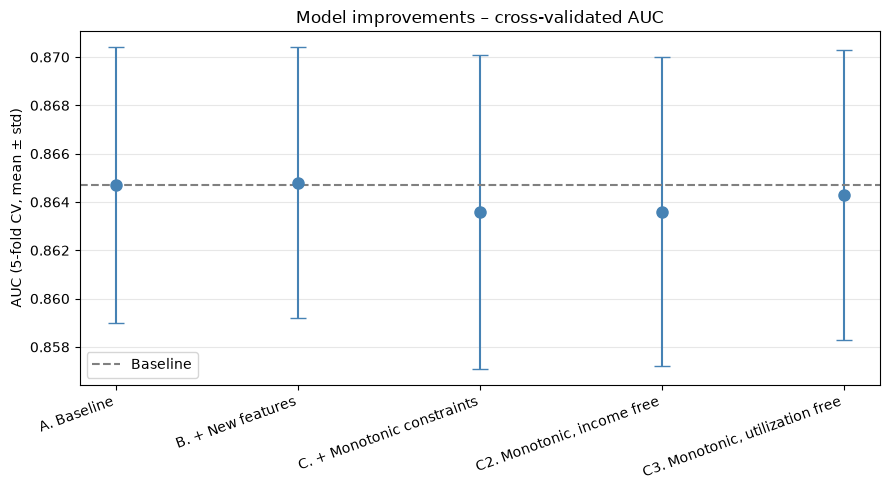

In [8]:
res = pd.DataFrame(resultados_cv)

plt.figure(figsize=(9, 5))
plt.errorbar(res["Model"], res["AUC mean"], yerr=res["AUC std"],
             fmt="o", capsize=6, markersize=8, color="steelblue")
plt.axhline(res.loc[0, "AUC mean"], color="gray", linestyle="--", label="Baseline")
plt.ylabel("AUC (5-fold CV, mean ± std)")
plt.title("Model improvements – cross-validated AUC")
plt.xticks(rotation=20, ha="right")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("../reports/figures/model_improvements_cv.png", dpi=150, bbox_inches="tight")
plt.show()

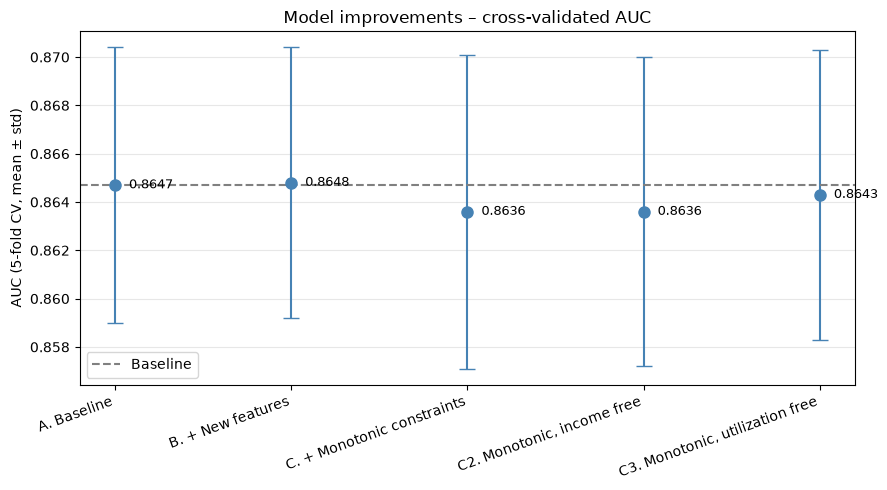

In [11]:
res = pd.DataFrame(resultados_cv)

plt.figure(figsize=(9, 5))
plt.errorbar(res["Model"], res["AUC mean"], yerr=res["AUC std"],
             fmt="o", capsize=6, markersize=8, color="steelblue")
plt.axhline(res.loc[0, "AUC mean"], color="gray", linestyle="--", label="Baseline")

for i, auc in enumerate(res["AUC mean"]):
    plt.text(i + 0.08, auc, f"{auc:.4f}", va="center", fontsize=9)

plt.ylabel("AUC (5-fold CV, mean ± std)")
plt.title("Model improvements – cross-validated AUC")
plt.xticks(rotation=20, ha="right")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("../reports/figures/model_improvements_cv.png", dpi=150, bbox_inches="tight")
plt.show()

## Conclusions

| Model | CV AUC (mean ± std) | CV Brier | Test AUC | Test Brier |
|---|---|---|---|---|
| A. Baseline XGBoost | 0.8647 ± 0.006 | 0.0491 | 0.8695 | 0.0487 |
| B. + New features | 0.8648 ± 0.006 | 0.0490 | – | – |
| C. + Monotonic constraints (all) | 0.8636 ± 0.007 | 0.0493 | – | – |
| C2. Monotonic, income free | 0.8636 ± 0.006 | 0.0493 | – | – |
| **C3. Monotonic, utilization free** | **0.8643 ± 0.006** | **0.0492** | **0.8697** | **0.0487** |

- **Feature engineering adds nothing to XGBoost** (+0.0001 AUC). Trees already build combinations such as total past-due events on their own; engineered features help linear models more than tree-based ones.
- **Monotonic constraints cost almost nothing when applied with judgment.** Forcing every expected direction lowers AUC by 0.0012, within the fold-to-fold noise (±0.006).
- **The EDA explained where the cost came from:** revolving utilization is not monotonic at the low end (borrowers with ~0% utilization default more than those with low positive usage, 2.52% vs. 1.35%). Leaving it unconstrained (C3) recovers most of the gap (−0.0005).
- **Final model: C3.** Same test performance as the baseline (AUC 0.8697 vs. 0.8695, identical Brier) while guaranteeing economically coherent behavior: more past-due events or debt can never lower the PD, and more age or income can never raise it. This makes the model easier to defend in a model validation or regulatory review.
- **The dataset is close to its ceiling** at ~0.87 AUC with the available features; further gains would require new information, not more complex models.